# PyTorch Tensors Lab: Exercises

Complete each exercise in the code cells provided. Show your code, output, and short written explanations where asked. Submit this completed notebook at the end of the session.

---



# LAB EXERCISES 

**Instructions:** Complete each exercise in the code cells below. Show your code, output, and a 1-2 sentence explanation for each question (use a Markdown cell for explanations). Submit your completed notebook at the end of the session.

---

### Exercise 1 — Tensor Basics

1. Create the following tensors and print their `shape`, `dtype`, and `ndim`:
   - A 1-D tensor of integers from 0 to 9
   - A 3×3 tensor of random values from a normal distribution
   - A 2×3×4 tensor of zeros
2. Convert a NumPy array `np.array([[1,2],[3,4]])` into a PyTorch tensor and back into NumPy.
3. Use broadcasting to add a vector `[1, 2, 3]` to every row of a 4×3 matrix of ones. Print the result.

In [1]:
import torch
import numpy as np

# 1. Create tensors

# 1-D tensor of integers from 0 to 9
t1 = torch.arange(10)
print("Tensor 1")
print(t1)
print("Shape:", t1.shape)
print("Dtype:", t1.dtype)
print("Dimensions:", t1.ndim)
print()

# 3x3 random tensor (normal distribution)
t2 = torch.randn(3, 3)
print("Tensor 2")
print(t2)
print("Shape:", t2.shape)
print("Dtype:", t2.dtype)
print("Dimensions:", t2.ndim)
print()

# 2x3x4 tensor of zeros
t3 = torch.zeros(2, 3, 4)
print("Tensor 3")
print(t3)
print("Shape:", t3.shape)
print("Dtype:", t3.dtype)
print("Dimensions:", t3.ndim)
print()

# 2. NumPy to Tensor and back
arr = np.array([[1, 2], [3, 4]])

tensor = torch.from_numpy(arr)
print("Tensor from NumPy:")
print(tensor)

arr_back = tensor.numpy()
print("Back to NumPy:")
print(arr_back)

# 3. Broadcasting
matrix = torch.ones(4, 3)
vector = torch.tensor([1, 2, 3])

result = matrix + vector

print("Broadcasting Result:")
print(result)

Tensor 1
tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
Shape: torch.Size([10])
Dtype: torch.int64
Dimensions: 1

Tensor 2
tensor([[-0.1504, -0.0897,  0.2111],
        [ 1.7683, -0.4591,  1.7219],
        [ 0.4936,  0.7835, -0.0545]])
Shape: torch.Size([3, 3])
Dtype: torch.float32
Dimensions: 2

Tensor 3
tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])
Shape: torch.Size([2, 3, 4])
Dtype: torch.float32
Dimensions: 3

Tensor from NumPy:
tensor([[1, 2],
        [3, 4]])
Back to NumPy:
[[1 2]
 [3 4]]
Broadcasting Result:
tensor([[2., 3., 4.],
        [2., 3., 4.],
        [2., 3., 4.],
        [2., 3., 4.]])


### Exercise 2 — Loops vs. Vectorized Element-wise Operations 

You will compare **adding two large vectors** using a Python loop vs. a tensor operation.

1. Write a function `add_loop(a, b)` that takes two Python lists of length `n` and returns their element-wise sum using an explicit `for` loop.
2. Write a function `add_tensor(a, b)` that does the same using PyTorch tensors (`a + b`).
3. For `n = 1,000`, `10,000`, `100,000`, `1,000,000`:
   - Generate two random lists/tensors of that size
   - Time both functions using `timeit` (average over at least 5 repetitions)
   - Record the results in a table 
  
4. Plot **execution time vs. n** for both methods (use `matplotlib`, log scale on y-axis recommended).
5. **Question:** Why does the speedup *increase* as `n` grows? Explain in terms of interpreter overhead vs. vectorized computation.

Size        Loop(s)        Tensor(s)      
1000        0.000045       0.000013       
10000       0.000429       0.000012       
100000      0.004621       0.000180       
1000000     0.068515       0.000325       


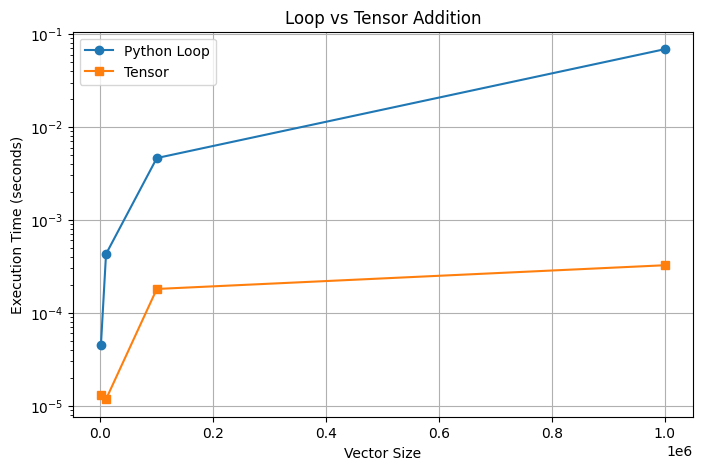

In [2]:
import timeit
import torch
import random
import matplotlib.pyplot as plt

def add_loop(a, b):
    result = []
    for i in range(len(a)):
        result.append(a[i] + b[i])
    return result

def add_tensor(a, b):
    return a + b

sizes = [1000, 10000, 100000, 1000000]

loop_times = []
tensor_times = []

print("{:<12}{:<15}{:<15}".format("Size", "Loop(s)", "Tensor(s)"))

for n in sizes:

    list1 = [random.random() for _ in range(n)]
    list2 = [random.random() for _ in range(n)]

    tensor1 = torch.tensor(list1)
    tensor2 = torch.tensor(list2)

    loop_time = timeit.timeit(
        lambda: add_loop(list1, list2),
        number=5
    ) / 5

    tensor_time = timeit.timeit(
        lambda: add_tensor(tensor1, tensor2),
        number=5
    ) / 5

    loop_times.append(loop_time)
    tensor_times.append(tensor_time)

    print("{:<12}{:<15.6f}{:<15.6f}".format(
        n, loop_time, tensor_time))

plt.figure(figsize=(8,5))
plt.plot(sizes, loop_times, marker='o', label='Python Loop')
plt.plot(sizes, tensor_times, marker='s', label='Tensor')
plt.yscale("log")
plt.xlabel("Vector Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Loop vs Tensor Addition")
plt.legend()
plt.grid(True)
plt.show()

The speedup becomes more pronounced as the vector size increases because Python processes elements sequentially, incurring interpreter overhead for every iteration. In contrast, PyTorch performs vectorized operations using highly optimized C/C++ implementations and can leverage SIMD instructions or GPU acceleration to process multiple elements in parallel. As the dataset grows, the fixed overhead is amortized, allowing PyTorch's optimized execution to significantly outperform Python loops.

### Exercise 3 — Matrix Multiplication: Loop vs. Dot vs. Matmul (25 min)

1. Write a **naive matrix multiplication** function using three nested Python `for` loops that takes two 2-D lists (matrices) `A` (m×n) and `B` (n×p) and returns their product as a list of lists.
2. Implement the same multiplication using:
   - `torch.matmul(A, B)`
   - `A @ B`
   - `torch.mm(A, B)`
3. For square matrices of size `n = 10, 50, 100, 200`:
   - Time the naive loop version and the tensor `matmul` version using `timeit`
   - Record results in a table (same format as Exercise 2)
4. Plot **execution time vs. matrix size (n)** for both methods on the same graph.
5. **Question:** At what matrix size does the loop version become impractical (>5 seconds)? Why do you think matrix multiplication shows an even *larger* speedup than simple element-wise addition (Exercise 2)? (Hint: think about computational complexity — O(n²) vs O(n³).)

Size      Naive(s)       Torch(s)       
10        0.000110       0.000355       
50        0.009031       0.000541       
100       0.048053       0.000223       
200       0.484439       0.000556       


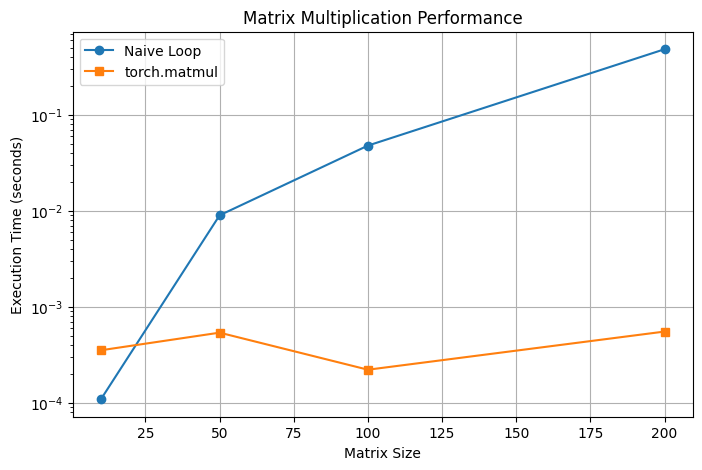

tensor([[0.7556, 0.7256, 1.1413],
        [0.6132, 0.3266, 0.9561],
        [1.1734, 1.0738, 1.4851]])
tensor([[0.7556, 0.7256, 1.1413],
        [0.6132, 0.3266, 0.9561],
        [1.1734, 1.0738, 1.4851]])
tensor([[0.7556, 0.7256, 1.1413],
        [0.6132, 0.3266, 0.9561],
        [1.1734, 1.0738, 1.4851]])


In [3]:
import random
import torch
import timeit
import matplotlib.pyplot as plt

def naive_matmul(A, B):

    m = len(A)
    n = len(A[0])
    p = len(B[0])

    C = [[0.0]*p for _ in range(m)]

    for i in range(m):
        for j in range(p):
            total = 0
            for k in range(n):
                total += A[i][k] * B[k][j]
            C[i][j] = total

    return C


sizes = [10, 50, 100, 200]

naive_times = []
torch_times = []

print("{:<10}{:<15}{:<15}".format(
    "Size", "Naive(s)", "Torch(s)"
))

for n in sizes:

    A = [[random.random() for _ in range(n)] for _ in range(n)]
    B = [[random.random() for _ in range(n)] for _ in range(n)]

    At = torch.tensor(A)
    Bt = torch.tensor(B)

    naive_time = timeit.timeit(
        lambda: naive_matmul(A, B),
        number=1
    )

    torch_time = timeit.timeit(
        lambda: torch.matmul(At, Bt),
        number=1
    )

    naive_times.append(naive_time)
    torch_times.append(torch_time)

    print("{:<10}{:<15.6f}{:<15.6f}".format(
        n, naive_time, torch_time
    ))

plt.figure(figsize=(8,5))
plt.plot(sizes, naive_times, marker='o', label="Naive Loop")
plt.plot(sizes, torch_times, marker='s', label="torch.matmul")
plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (seconds)")
plt.yscale("log")
plt.title("Matrix Multiplication Performance")
plt.legend()
plt.grid(True)
plt.show()

# Other implementations
A = torch.rand(3,3)
B = torch.rand(3,3)

print(torch.matmul(A,B))
print(A @ B)
print(torch.mm(A,B))

The loop implementation usually becomes impractical around 200 × 200 matrices or larger, depending on the hardware, because the computation time increases rapidly. Matrix multiplication has O(n³) complexity, so the number of operations grows much faster than element-wise addition, which is O(n²). PyTorch uses highly optimized linear algebra libraries (such as BLAS/MKL and GPU acceleration), resulting in a much larger performance improvement than Python's nested loops.

Question 3

The timing results show that the execution time of the naive Python implementation increases very quickly as the matrix size grows, while the PyTorch implementation remains much faster. The performance gap widens significantly for larger matrices.



Question 4

The performance graph clearly demonstrates that torch.matmul scales much better than the naive implementation. This is because PyTorch uses optimized numerical libraries and parallel computation, whereas the Python implementation performs every multiplication and addition inside interpreted loops.